# Learner and FashionMNIST

## Dataset and DataLoader

In [1]:
from pathlib import Path
import kagglehub

# Download latest version
path = kagglehub.dataset_download("zalando-research/fashionmnist")

print("Path to dataset files:", path)
path = Path(path)

Path to dataset files: C:\Users\marcinzi\.cache\kagglehub\datasets\zalando-research\fashionmnist\versions\4


In [2]:
from torch.utils.data import Dataset, DataLoader
import torch

class FashionMNIST_DS(Dataset):
    def __init__(self, path:Path):
        import pandas as pd
        df = pd.read_csv(path)
        self.labels = torch.tensor(df['label'].values, dtype=torch.long).cuda()
        self.data = torch.tensor(df.drop('label', axis=1).values, dtype=torch.float).cuda()

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        return self.data[idx], self.labels[idx]

train_ds, valid_ds = FashionMNIST_DS(path/'fashion-mnist_train.csv'), FashionMNIST_DS(path/'fashion-mnist_test.csv')

train_dl = DataLoader(train_ds, batch_size=256, shuffle=True)
valid_dl = DataLoader(valid_ds, batch_size=256*2)

dataloaders = {
    'train': train_dl,
    'valid': valid_dl
}

class_names = ['T_shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 
               'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

c:\src\mrcn-zmnsk-playground\.venv\Lib\site-packages\torch\cuda\__init__.py:63: FutureWarning: The pynvml package is deprecated. Please install nvidia-ml-py instead. If you did not install pynvml directly, please report this to the maintainers of the package that installed pynvml for you.
  import pynvml  # type: ignore[import]


## Image Display

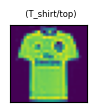

In [26]:
import matplotlib.pyplot as plt

def show_image(img, expected_label, actual_label=None, ax=None):
    show=False
    img = img.reshape(28, 28)
    
    fontweight = "normal" if actual_label is None or actual_label == expected_label else "bold"  # highlight when model misses
    actual_label = class_names[actual_label] if actual_label is not None else ' '
    expected_label = class_names[expected_label] 

    if ax is None:
        _, ax = plt.subplots(figsize=(1,1))
        show=True

    ax.set_xticks([])
    ax.set_yticks([])
    ax.grid(False)    
    ax.imshow(img)
    ax.set_title(f'{actual_label} ({expected_label})', fontweight=fontweight, fontsize=6)

    if show: plt.show()

data, label = valid_ds[0]
show_image(data.cpu(), label.cpu())

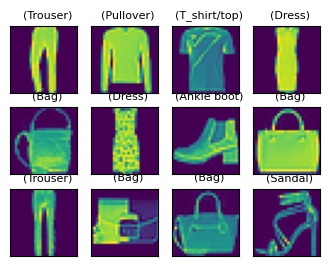

In [10]:
import matplotlib.pyplot as plt
import math
import torch

def show_images(images, expected_labels, actual_labels=None):
    size = len(images)
    rows = math.floor(math.sqrt(size))
    cols = math.ceil(size / rows)
    _, axs = plt.subplots(rows, cols, figsize=(cols, rows))

    axs = axs.ravel()

    for i,img in enumerate(images):
        
        expected_label = expected_labels[i]
        actual_label = actual_labels[i] if actual_labels is not None else None

        show_image(img.cpu(), expected_label.cpu(), actual_label.cpu() if actual_label else None , ax=axs[i])

    plt.show()

rand_idx = torch.randperm(len(train_ds))[:12]
batch = train_ds[rand_idx]
show_images(batch[0], batch[1])

## Visitors

In [11]:
class LearnerVisitor():
    def beforeEpoch(self, learner):
        pass
    def afterEpoch(self, learner):
        pass
    def beforeBatch(self, learner):
        pass
    def afterBatch(self, learner):
        pass
    def beforeFit(self, learner):
        pass
    def afterFit(self, learner):
        pass
    
class with_visitors:
    def __init__(self, phase):
        self.phase = phase

    def __call__(self, f):
        def _f(learner, *args, **kwargs):
            if self.phase == "fit":
                _ = [ cb.beforeFit(learner) for cb in learner.visitors ]
            elif self.phase == "epoch":
                _ = [ cb.beforeEpoch(learner) for cb in learner.visitors ]
            elif self.phase == "batch":
                _ = [ cb.beforeBatch(learner) for cb in learner.visitors ]
            result = f(learner, *args, **kwargs)
            if self.phase == "batch":
                _ = [ cb.afterBatch(learner) for cb in learner.visitors ]
            elif self.phase == "epoch":
                _ = [ cb.afterEpoch(learner) for cb in learner.visitors ]
            elif self.phase == "fit":
                _ = [ cb.afterFit(learner) for cb in learner.visitors ]
            return result
        return _f

### LearningRate

In [12]:
class LearningCancelledException(Exception): pass

class LearningRateVisitor(LearnerVisitor):
    def __init__(self, exp=1.3):
        import math
        self.exp = exp
        self.min_loss = math.inf

    def beforeEpoch(self, learner):
        self.losses, self.lrs = [], []

    def afterBatch(self, learner):
        loss = learner.loss.item()
        lr = learner.opt.param_groups[0]['lr']

        self.losses.append(loss)
        self.lrs.append(lr)

        if loss > 4 * self.min_loss: raise LearningCancelledException()
        
        self.min_loss = min(self.min_loss, loss)

        for param_group in learner.opt.param_groups:
            param_group['lr'] *= self.exp

    def print(self):
        import matplotlib.pyplot as plt
        plt.plot(self.lrs, self.losses)
        plt.xscale('log')
        plt.xlabel('Learning Rate')
        plt.ylabel('Loss')
        plt.show()

### Metrics

In [ ]:
from torcheval.metrics import Mean, MulticlassAccuracy
import matplotlib.pyplot as plt
from IPython.display import display
import pandas as pd


class MetricsVisitor(LearnerVisitor):
    def __init__(self, **metrics):
        self.metrics = metrics
        self.train_histograms = { 'loss' : [] }
        self.valid_histograms = { 'loss' : [] }
        for metric in self.metrics.keys():
            self.train_histograms[metric] = []
            self.valid_histograms[metric] = []

        self.df = pd.DataFrame(columns=['epoch', 'training', 'loss'] + list(self.metrics.keys()))
        
        self.fig, self.axs = plt.subplots(len(self.valid_histograms), sharex=True)
        self.plotHandle = display(self.fig, display_id=True)
        self.tableHandle = display(self.df, display_id=True)
        self.plot()
        

    def beforeEpoch(self, learner):
        [m.reset() for m in self.metrics.values()]
        self.loss = Mean(device='cuda')
        
    def afterEpoch(self, learner):
        result = { name: round(metric.compute().item(), 4) for name, metric in self.metrics.items() }
        histograms = self.train_histograms if learner.training else self.valid_histograms
        [histograms[name].append(value) for name, value in result.items()]
        loss = self.loss.compute().item()
        histograms['loss'].append(loss)
        result['epoch'] = learner.epoch
        result['training'] = learner.training
        result['loss'] = round(loss, 4)
        
        self.df.loc[len(self.df)] = result
                
        self.update_visuals()

    def update_visuals(self):
        
        self.tableHandle.update(self.df)

        i=0
        for name in self.valid_histograms.keys():
            ax = self.axs[i]
            ax.clear()
            l_t = len(self.train_histograms[name])
            l_v = len(self.valid_histograms[name])
            ax.plot(range(l_t), self.train_histograms[name], label='train')
            ax.plot(range(l_v), self.valid_histograms[name], label='valid')
            ax.set_xlabel("epoch")
            ax.set_xticks(range(max(l_t, l_v)))
            ax.set_ylabel(name)
            ax.legend()
            i+=1
        self.plotHandle.update(self.fig)
                                     
    def afterBatch(self, learner):
        [m.update(learner.preds.argmax(1), learner.yb) for m in self.metrics.values()]
        self.loss.update(learner.loss)

    def afterFit(self, learner):
        plt.close(self.fig)

### ActivationsVisitor

In [153]:
class ActivationsVisitor(LearnerVisitor):
    def afterEpoch(self, learner):
        x = learner.model.parameters()

### Progress Tracker

In [146]:
from tqdm.auto import tqdm

class ProgressVisitor(LearnerVisitor):

    def __init__(self):
        self.epochs_bar = None

    def beforeEpoch(self, learner):
        if self.epochs_bar is None:
            self.epochs_bar = tqdm(total=learner.epochs*2, desc="Training progress", leave=True)
        
        dl = learner.data_loaders['train'] if learner.training else learner.data_loaders['valid']
        self.epoch_bar = tqdm(
            total=len(dl), 
            desc=f"Epoch {learner.epoch} - {'Train' if learner.training else 'Validation'}", 
            leave=False
        )
        self.running_loss = 0.

    def afterEpoch(self, learner):
        self.epochs_bar.update(1)
        self.epoch_bar.close()

    def afterBatch(self, learner):
        self.running_loss += learner.loss.item()
        self.epoch_bar.update(1)
        self.epoch_bar.set_postfix(loss=f"{self.running_loss / (self.epoch_bar.n):.4f}")


## Learner

In [149]:
from torch import optim
from torch import nn
from torch.optim.lr_scheduler import CosineAnnealingLR


class Learner:
    def __init__(self, model: nn.Module, data_loaders, loss_func, lr, opt_func=optim.SGD, visitors = [], batch_transform = (lambda xb: xb), scheduler_func=None):
        self.model = model
        self.data_loaders = data_loaders
        self.loss_func = loss_func
        self.lr = lr
        self.opt_func = opt_func        
        self.visitors = visitors
        self.batch_transform = batch_transform 
        

    @with_visitors("batch")
    def one_batch(self, batch_number, training=True):
        self.preds = self.model(self.xb)
        self.loss = self.loss_func(self.preds, self.yb)
        if training:            
            self.loss.backward()
            self.opt.step()
            self.opt.zero_grad()
            self.scheduler.step()

    @with_visitors("epoch")
    def one_epoch(self):
        self.data_loader = self.data_loaders['train'] if self.training else self.data_loaders['valid']

        for b_i, batch in enumerate(self.data_loader):
            xb, self.yb = batch
            self.xb = self.batch_transform(xb)
            self.one_batch(b_i, self.training)

    @with_visitors("fit")
    def fit(self, epochs: int):
        self.epochs = epochs
        self.accuracies, self.losses, self.counts = [], [], []

        self.opt = self.opt_func(self.model.parameters(), lr=self.lr)       
        self.scheduler = CosineAnnealingLR(self.opt, T_max=epochs)
        
        for self.epoch in range(epochs):
            self.training = True
            self.one_epoch()
            self.training = False
            self.one_epoch()
        
    def predict(self, x):
        self.model.eval()
        return self.model( self.batch_transform(x) )
    
    def findLR(self, fromLR = 0.0001):
        visitors_backup = self.visitors.copy()
        lr_backup, self.lr = self.lr, fromLR
                
        try:
            lr_visitor = LearningRateVisitor()
            self.visitors = [lr_visitor]
            self.fit(1)
        except LearningCancelledException:
            pass
        finally:
            self.visitors = visitors_backup
            self.lr = lr_backup
        
        lr_visitor.print()         



## MNIST Fashion Classifier

### Neural Net - linear

In [ ]:
import torch.nn.functional as F

m,nh1,nh2=28*28, 512, 256
model = nn.Sequential(
    nn.Linear(m, nh1),
    nn.ReLU(),
    nn.BatchNorm1d(nh1),
    nn.Linear(nh1, nh2),
    nn.ReLU(),
    nn.BatchNorm1d(nh2),
    nn.Linear(nh2, 10)
).cuda()

In [ ]:
learner = Learner(model, dataloaders, F.cross_entropy, lr=0.3, visitors=[MetricsVisitor(accuracy=MulticlassAccuracy())])

C:\Users\marcinzi\AppData\Local\Temp\ipykernel_80620\415518726.py:15: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  return torch.tensor(self.data[idx]).cuda(), torch.tensor(self.labels[idx]).cuda()


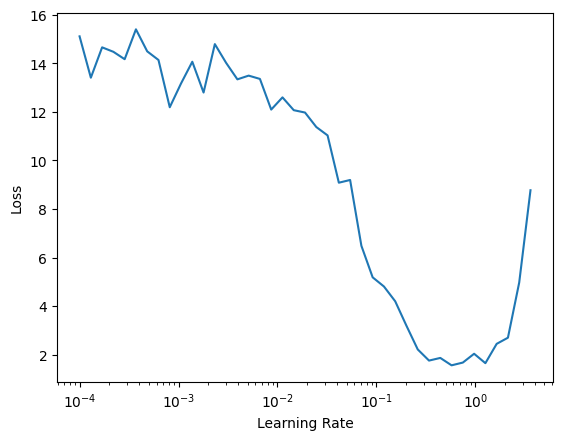

In [19]:
learner.findLR()

In [21]:
learner.fit(10)

C:\Users\marcinzi\AppData\Local\Temp\ipykernel_80620\415518726.py:15: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  return torch.tensor(self.data[idx]).cuda(), torch.tensor(self.labels[idx]).cuda()


{'accuracy': 0.7298, 'loss': 0.8315, 'epoch': 0, 'train': True}
{'accuracy': 0.7741, 'loss': 0.6301, 'epoch': 0, 'train': False}
{'accuracy': 0.8021, 'loss': 0.5518, 'epoch': 1, 'train': True}
{'accuracy': 0.8101, 'loss': 0.5379, 'epoch': 1, 'train': False}
{'accuracy': 0.8202, 'loss': 0.5004, 'epoch': 2, 'train': True}
{'accuracy': 0.8221, 'loss': 0.4979, 'epoch': 2, 'train': False}
{'accuracy': 0.8296, 'loss': 0.4716, 'epoch': 3, 'train': True}
{'accuracy': 0.8336, 'loss': 0.4639, 'epoch': 3, 'train': False}
{'accuracy': 0.8353, 'loss': 0.4565, 'epoch': 4, 'train': True}
{'accuracy': 0.8254, 'loss': 0.4763, 'epoch': 4, 'train': False}
{'accuracy': 0.8413, 'loss': 0.4414, 'epoch': 5, 'train': True}
{'accuracy': 0.8407, 'loss': 0.4509, 'epoch': 5, 'train': False}
{'accuracy': 0.8458, 'loss': 0.4276, 'epoch': 6, 'train': True}
{'accuracy': 0.8432, 'loss': 0.434, 'epoch': 6, 'train': False}
{'accuracy': 0.851, 'loss': 0.4135, 'epoch': 7, 'train': True}
{'accuracy': 0.8474, 'loss': 0.4307

C:\Users\marcinzi\AppData\Local\Temp\ipykernel_80620\415518726.py:15: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  return torch.tensor(self.data[idx]).cuda(), torch.tensor(self.labels[idx]).cuda()


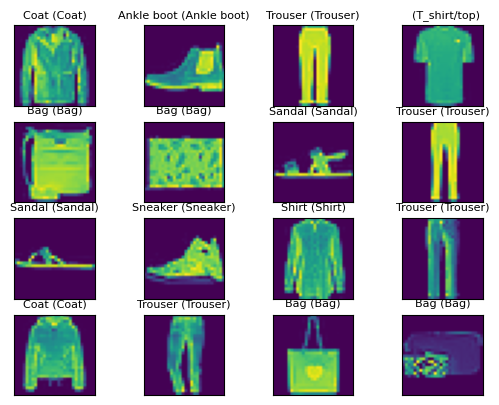

In [23]:
sample = torch.randperm(len(valid_ds))[:16]
input = valid_ds[sample]
pred = learner.predict(input[0]).argmax(1)

show_images(input[0], input[1], pred)

### Convolutional Neural Net

In [150]:
def conv(in_ch, out_ch, kernel_size=5, stride=4, padding=2):
    return nn.Sequential(
        nn.Conv1d(in_ch, out_ch, kernel_size=kernel_size, stride=stride, padding=padding),
        nn.ReLU(),
        nn.BatchNorm1d(out_ch)
    )

# starts at 1d input = 28*28 = 784
cnn_model = nn.Sequential(
    conv(1,8),  # 196
    conv(8,16),  # 49
    conv(16,32),  # 13
    conv(32,64),  # 4
    conv(64,10),  # 1
    nn.Flatten()
).cuda()
    

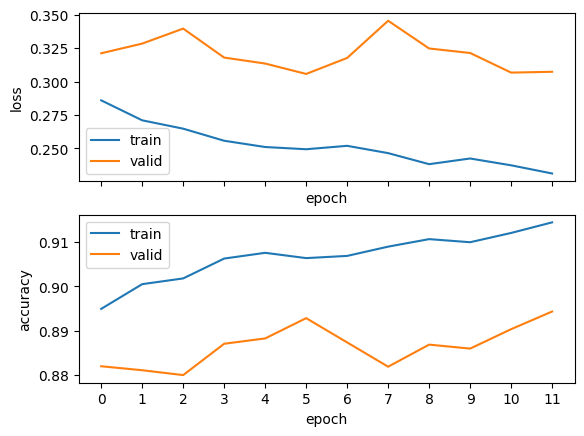

,epoch,training,loss,accuracy
0,0,True,0.2860,0.8949
1,0,False,0.3212,0.8819
2,1,True,0.2710,0.9005
3,1,False,0.3285,0.8810
4,2,True,0.2648,0.9018
5,2,False,0.3397,0.8799
6,3,True,0.2557,0.9063
7,3,False,0.3180,0.8870
8,4,True,0.2510,0.9076
9,4,False,0.3135,0.8882


Training progress:   0%|          | 0/24 [00:00<?, ?it/s]

Epoch 0 - Train:   0%|          | 0/235 [00:00<?, ?it/s]

Epoch 0 - Validation:   0%|          | 0/20 [00:00<?, ?it/s]

Epoch 1 - Train:   0%|          | 0/235 [00:00<?, ?it/s]

...

Epoch 9 - Validation:   0%|          | 0/20 [00:00<?, ?it/s]

Epoch 10 - Train:   0%|          | 0/235 [00:00<?, ?it/s]

Epoch 10 - Validation:   0%|          | 0/20 [00:00<?, ?it/s]

Epoch 11 - Train:   0%|          | 0/235 [00:00<?, ?it/s]

Epoch 11 - Validation:   0%|          | 0/20 [00:00<?, ?it/s]

In [156]:
import torch.nn.functional as F

def batch_transform_cnn(xb):
    return xb.view(xb.size(0), 1, -1)

cnn_learner = Learner(cnn_model, dataloaders, F.cross_entropy, lr=0.1, visitors=[ProgressVisitor(), MetricsVisitor(accuracy=MulticlassAccuracy()), ActivationsVisitor()], batch_transform=batch_transform_cnn, opt_func=optim.Adam)

cnn_learner.fit(12)

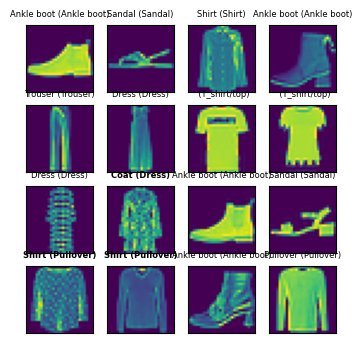

In [152]:
sample = torch.randperm(len(valid_ds))[:16]
input = valid_ds[sample]
pred = cnn_learner.predict(input[0]).argmax(1)

show_images(input[0], input[1], pred)